# FA084 — Mineração de Dados

## Algoritmo Genético — Alocação de Grade de Disciplinas

**Aluno:** Leonardo Teixeira
**RA:** 245602
**UNICAMP**

---

**Correspondência com os itens do enunciado:**

| Item do enunciado | Seção deste notebook |
|---|---|
| 1 — montar `tab_professores.txt` | 3 |
| 2 — leitura do TXT para o dicionário | 3 |
| 3 — função de custo / fitness | 6 |
| 4 — mutação e cruzamento no domínio do problema | 7, 8 e 9 |
| 5 — algoritmo genético adaptado ao problema | 7 |
| 6 — execução com a configuração oficial | 10, 11 e 12 |
| 7 — quais parâmetros modificar | 13 |
| 8 — implementar a modificação e comparar com o item 6 | 14 |

## 1. Objetivo

Montar a grade semanal de aulas **com o menor custo possível**. A cada dia, de segunda a sexta, é preciso escolher uma disciplina e um professor para ministrá-la. A busca é feita por um **algoritmo genético (AG)**, que mantém uma população de grades candidatas e as melhora ao longo das gerações por seleção, cruzamento e mutação.

Cada grade é avaliada por uma função de fitness que soma o custo dos professores alocados e aplica penalidades quando a grade viola as regras do enunciado. **Quanto menor o fitness, melhor a grade.**

## 2. Descrição do problema

- **Disciplinas a cursar:** numeradas de 1 a 20.
- **Dias de aula:** 5 — segunda, terça, quarta, quinta e sexta.
- **Em cada dia:** uma única aula, isto é, uma disciplina e um professor.
- **Professores:** 10, cada um com um custo por aula e um conjunto de disciplinas que já ministrou.
- **Custo de um dia:** é o custo do professor alocado naquele dia. Exemplo do enunciado: alocar o professor 3 na segunda-feira, para a disciplina 2, custa R\$ 60,00.
- **Regras**, penalizadas por fatores multiplicativos:
  - ×2 se uma disciplina for dada por um professor que nunca a ministrou;
  - ×1,5 se o mesmo professor for escolhido para mais de uma disciplina;
  - ×5 se a mesma disciplina aparecer em dias diferentes.
- **Objetivo:** minimizar o fitness, que é o custo total da semana multiplicado pelas penalidades que incidirem.

## 3. Dados (itens 1 e 2)

A tabela de professores do enunciado foi transcrita para o arquivo `tab_professores.txt` (item 1). Há uma linha por professor, no formato pedido: `professor, custo, disciplina1, disciplina2, ...`. Por exemplo, o professor 1 fica como `1,89,1,3,6,8,12,15,17,20`. As 10 linhas foram conferidas célula a célula com a tabela do enunciado.

A leitura do arquivo preenche um dicionário (item 2) no formato `{professor: {"custo": custo, "disciplinas": {conjunto de disciplinas}}}`. O arquivo fica em `data/tab_professores.txt`, com caminho relativo à pasta deste notebook.

In [1]:
import random
import statistics
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import fisher_exact, wilcoxon

pd.set_option("display.max_columns", None)

ARQUIVO_PROFESSORES = Path("data") / "tab_professores.txt"


def carregar_professores(caminho):
    professores = {}
    with open(caminho, encoding="utf-8") as arquivo:
        for linha in arquivo:
            if not linha.strip():
                continue
            professor, custo, *disciplinas = (int(v) for v in linha.split(",") if v.strip())
            professores[professor] = {"custo": custo, "disciplinas": set(disciplinas)}
    return professores


professores = carregar_professores(ARQUIVO_PROFESSORES)

display(pd.DataFrame(
    [(p, info["custo"], ", ".join(map(str, sorted(info["disciplinas"])))) for p, info in professores.items()],
    columns=["Professor", "Custo por aula (R$)", "Disciplinas que já ministrou"],
).set_index("Professor"))

,Custo por aula (R$),Disciplinas que já ministrou
Professor,,
1,89,"1, 3, 6, 8, 12, 15, 17, 20"
2,80,"2, 10, 14, 19"
3,60,"2, 4, 6, 9, 11, 13, 15, 17"
4,50,"1, 5, 10, 18"
5,85,"3, 5, 6, 9, 10, 12, 15, 17"
6,65,"12, 13, 15, 16, 19, 20"
7,70,"2, 3, 5, 8, 11, 17"
8,69,"1, 4, 7, 9, 11, 15"
9,88,"1, 3, 4, 5, 6, 7, 10, 12, 13, 14, 16, 17, 19, 20"


## 4. Representação do cromossomo

Cada indivíduo da população é uma grade completa da semana, codificada como uma lista de **10 genes** que formam **5 pares (P, D)**, um por dia:

```
[ P,D , P,D , P,D , P,D , P,D ]
  Seg   Ter   Qua   Qui   Sex
```

- **P** é o número do professor, com domínio [1, 10]. Ocupa as posições pares da lista: 0, 2, 4, 6 e 8.
- **D** é o número da disciplina, com domínio [1, 20]. Ocupa as posições ímpares: 1, 3, 5, 7 e 9.

In [2]:
DIAS_SEMANA = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta"]
NUM_DIAS = len(DIAS_SEMANA)          # 5 pares (P, D) -> 10 genes
NUM_PROFESSORES = len(professores)   # domínio de P: [1, 10]
NUM_DISCIPLINAS = 20                 # domínio de D: [1, 20], conforme o enunciado


def pares(cromossomo):
    return [(cromossomo[2 * i], cromossomo[2 * i + 1]) for i in range(NUM_DIAS)]

## 5. Cromossomo inicial

O enunciado define o cromossomo inicial `[3,2 , 8,9 , 1,12 , 10,14 , 8,4]`. Ele entra na população inicial do AG junto com indivíduos aleatórios (seção 7).

In [3]:
cromossomo_inicial = [3, 2, 8, 9, 1, 12, 10, 14, 8, 4]

print(f"Cromossomo inicial: {cromossomo_inicial} ({len(cromossomo_inicial)} genes)\n")
for dia, (p, d) in zip(DIAS_SEMANA, pares(cromossomo_inicial)):
    ja_ministrou = "sim" if d in professores[p]["disciplinas"] else "NÃO"
    print(f"  {dia:8s}: professor {p:2d} (R$ {professores[p]['custo']}) -> disciplina {d:2d} | já ministrou? {ja_ministrou}")

Cromossomo inicial: [3, 2, 8, 9, 1, 12, 10, 14, 8, 4] (10 genes)

  Segunda : professor  3 (R$ 60) -> disciplina  2 | já ministrou? sim
  Terça   : professor  8 (R$ 69) -> disciplina  9 | já ministrou? sim
  Quarta  : professor  1 (R$ 89) -> disciplina 12 | já ministrou? sim
  Quinta  : professor 10 (R$ 76) -> disciplina 14 | já ministrou? NÃO
  Sexta   : professor  8 (R$ 69) -> disciplina  4 | já ministrou? sim


## 6. Função de fitness (item 3)

A implementação segue a função de fitness definida no enunciado:

F = (×2, se prof_nunca_ministrou) × (×1,5, se prof_repetido) × (×5, se disciplina_repetida) × (custo_aula_seg + custo_aula_ter + custo_aula_qua + custo_aula_qui + custo_aula_sex)

- **Custo base (função de custo):** soma dos custos dos professores dos 5 dias.
- **Fatores:** cada fator vale o número indicado quando sua condição ocorre em qualquer dia da grade, e 1 quando não ocorre. Os três podem ocorrer juntos e, nesse caso, se multiplicam (ex.: ×2 × 1,5 = ×3).
- **Minimização:** quanto menor F, melhor a grade.

As funções `tabela_grade` e `tabela_fitness` só apresentam uma grade, dia a dia e fator a fator; elas não alteram o cálculo.

In [4]:
def custo_base(cromossomo, professores):
    return sum(professores[p]["custo"] for p, _ in pares(cromossomo))


def fatores_penalidade(cromossomo, professores):
    dias = pares(cromossomo)
    nunca_ministrou = any(d not in professores[p]["disciplinas"] for p, d in dias)
    professor_repetido = len({p for p, _ in dias}) < NUM_DIAS
    disciplina_repetida = len({d for _, d in dias}) < NUM_DIAS
    return (2.0 if nunca_ministrou else 1.0,
            1.5 if professor_repetido else 1.0,
            5.0 if disciplina_repetida else 1.0)


def funcao_fitness(cromossomo, professores):
    fator_nunca_ministrou, fator_prof_repetido, fator_disc_repetida = fatores_penalidade(cromossomo, professores)
    return fator_nunca_ministrou * fator_prof_repetido * fator_disc_repetida * custo_base(cromossomo, professores)


def tabela_grade(cromossomo, professores):
    dias = pares(cromossomo)
    lista_p = [p for p, _ in dias]
    lista_d = [d for _, d in dias]
    linhas = []
    for dia, (p, d) in zip(DIAS_SEMANA, dias):
        penalizacoes = []
        if d not in professores[p]["disciplinas"]:
            penalizacoes.append("professor nunca ministrou (×2)")
        if lista_p.count(p) > 1:
            penalizacoes.append("professor repetido (×1,5)")
        if lista_d.count(d) > 1:
            penalizacoes.append("disciplina repetida (×5)")
        linhas.append({"Dia": dia, "Professor": p, "Disciplina": d,
                       "Custo (R$)": professores[p]["custo"],
                       "Penalizações": "; ".join(penalizacoes) or "—"})
    return pd.DataFrame(linhas).set_index("Dia")


def tabela_fitness(cromossomo, professores):
    f2, f15, f5 = fatores_penalidade(cromossomo, professores)
    return pd.DataFrame([{
        "Custo base (R$)": custo_base(cromossomo, professores),
        "Fator prof. nunca ministrou (×2)": f2,
        "Fator prof. repetido (×1,5)": f15,
        "Fator disc. repetida (×5)": f5,
        "Fitness F": funcao_fitness(cromossomo, professores),
    }], index=["valor"])


print("Fitness do cromossomo inicial:")
display(tabela_grade(cromossomo_inicial, professores))
display(tabela_fitness(cromossomo_inicial, professores))

Fitness do cromossomo inicial:


,Professor,Disciplina,Custo (R$),Penalizações
Dia,,,,
Segunda,3,2,60,—
Terça,8,9,69,"professor repetido (×1,5)"
Quarta,1,12,89,—
Quinta,10,14,76,professor nunca ministrou (×2)
Sexta,8,4,69,"professor repetido (×1,5)"


,Custo base (R$),Fator prof. nunca ministrou (×2),"Fator prof. repetido (×1,5)",Fator disc. repetida (×5),Fitness F
valor,363,2.0,1.5,1.0,1089.0


### 6.1 Menor valor possível de F (ótimo global)

Para avaliar os resultados do AG, é útil saber qual é o menor F possível. Não é viável testar todos os cromossomos: com 200 pares (P, D) possíveis por dia, são 200⁵ ≈ 3,2 × 10¹¹ combinações. O ótimo pode ser demonstrado em duas partes: **(i)** um limite inferior válido para qualquer cromossomo; **(ii)** um cromossomo que atinge esse limite.

**(i) Limite inferior.** Todo cromossomo se encaixa em exatamente um dos três casos abaixo:

- **Caso A — algum professor aparece em mais de um dia.** O fator ×1,5 incide obrigatoriamente, e os demais fatores são ≥ 1 mesmo quando também incidem. Cada dia custa no mínimo o menor custo da tabela. Logo, **F ≥ 5 × (menor custo) × 1,5**.
- **Caso B — 5 professores distintos, mas com algum professor que nunca ministrou sua disciplina e/ou alguma disciplina repetida.** Incide ao menos um fator ×2 ou ×5, então o multiplicador é ≥ 2. O custo base de 5 professores distintos é, no mínimo, a soma dos 5 menores custos. Logo, **F ≥ (soma dos 5 menores custos) × 2**.
- **Caso C — 5 professores distintos, todos já ministraram a disciplina alocada, e 5 disciplinas distintas.** Nenhum fator incide, e F é exatamente o custo base. O código testa **todos** os C(10, 5) = 252 grupos de 5 professores distintos. Para cada grupo, uma busca com retrocesso (*backtracking*) verifica se existe uma atribuição de 5 disciplinas distintas que os professores já ministraram. O menor custo base entre os grupos viáveis é o mínimo exato do caso C.

A ordem dos dias não altera F, porque custos e penalidades não dependem do dia. Os três casos cobrem todos os cromossomos: ou há professor repetido (A) ou não há; e, sem professor repetido, há penalidade (B) ou não há (C). Portanto, **L = min(limite A, limite B, mínimo do caso C)** é um limite inferior para qualquer cromossomo.

**(ii) Solução que atinge o limite.** O grupo e as disciplinas encontrados no caso C formam um cromossomo, que é avaliado pela própria `funcao_fitness`. Se F(cromossomo) = L, então L é o ótimo global.

In [5]:
custos_ordenados = sorted(info["custo"] for info in professores.values())

limite_A = NUM_DIAS * custos_ordenados[0] * 1.5          # caso A: professor repetido
limite_B = sum(custos_ordenados[:NUM_DIAS]) * 2          # caso B: distintos, com penalidade


def atribuicao_valida(grupo, professores):
    """Backtracking: uma disciplina distinta, já ministrada, para cada professor do grupo (ou None)."""
    def buscar(i, usadas):
        if i == len(grupo):
            return []
        for d in sorted(professores[grupo[i]]["disciplinas"] - usadas):
            resto = buscar(i + 1, usadas | {d})
            if resto is not None:
                return [d] + resto
        return None
    return buscar(0, set())


todos_os_grupos = list(combinations(sorted(professores), NUM_DIAS))
grupos_viaveis = []
for grupo in todos_os_grupos:
    disciplinas = atribuicao_valida(grupo, professores)
    if disciplinas is not None:
        grupos_viaveis.append((sum(professores[p]["custo"] for p in grupo), grupo, disciplinas))
grupos_viaveis.sort()
minimo_C, grupo_otimo, disciplinas_otimas = grupos_viaveis[0]   # caso C: mínimo exato

limite_inferior = min(limite_A, limite_B, minimo_C)

print(f"Caso A (professor repetido):                 F >= {NUM_DIAS} x {custos_ordenados[0]} x 1,5 = {limite_A:g}")
print(f"Caso B (distintos, com penalidade x2 ou x5): F >= {sum(custos_ordenados[:NUM_DIAS])} x 2 = {limite_B:g}")
print(f"Caso C (distintos, sem penalidade):          {len(grupos_viaveis)} de {len(todos_os_grupos)} grupos admitem "
      f"grade sem penalidades; menor custo base = {minimo_C} (professores {list(grupo_otimo)})")
print(f"Limite inferior para qualquer cromossomo:    L = min({limite_A:g}, {limite_B:g}, {minimo_C}) = {limite_inferior:g}")

Caso A (professor repetido):                 F >= 5 x 50 x 1,5 = 375
Caso B (distintos, com penalidade x2 ou x5): F >= 314 x 2 = 628
Caso C (distintos, sem penalidade):          252 de 252 grupos admitem grade sem penalidades; menor custo base = 314 (professores [3, 4, 6, 7, 8])
Limite inferior para qualquer cromossomo:    L = min(375, 628, 314) = 314


In [6]:
cromossomo_otimo = [gene for p, d in zip(grupo_otimo, disciplinas_otimas) for gene in (p, d)]
fitness_cromossomo_otimo = funcao_fitness(cromossomo_otimo, professores)

print("Cromossomo encontrado pelo backtracking:", cromossomo_otimo)
display(tabela_grade(cromossomo_otimo, professores))
display(tabela_fitness(cromossomo_otimo, professores))

assert fitness_cromossomo_otimo == limite_inferior, "o cromossomo não atinge o limite inferior: a demonstração não se fecha"
OTIMO_GLOBAL = fitness_cromossomo_otimo
print(f"F(cromossomo) = {fitness_cromossomo_otimo:g} = L  =>  ótimo global: F* = {OTIMO_GLOBAL:g}")

Cromossomo encontrado pelo backtracking: [3, 2, 4, 1, 6, 12, 7, 3, 8, 4]


,Professor,Disciplina,Custo (R$),Penalizações
Dia,,,,
Segunda,3,2,60,—
Terça,4,1,50,—
Quarta,6,12,65,—
Quinta,7,3,70,—
Sexta,8,4,69,—


,Custo base (R$),Fator prof. nunca ministrou (×2),"Fator prof. repetido (×1,5)",Fator disc. repetida (×5),Fitness F
valor,314,1.0,1.0,1.0,314.0


F(cromossomo) = 314 = L  =>  ótimo global: F* = 314


**Resultado:**

- **(i) Limite inferior.** Para qualquer cromossomo, **L = 314**. Os limites dos casos A e B, 375 e 628, são maiores que o mínimo do caso C.
- **(ii) Solução que atinge o limite.** O menor custo do caso C vem dos 5 professores mais baratos: 3, 4, 6, 7 e 8, com custos 60 + 50 + 65 + 70 + 69 = 314. O backtracking encontrou para eles 5 disciplinas distintas que cada um já ministrou. Avaliado pela `funcao_fitness`, o cromossomo `[3,2 , 4,1 , 6,12 , 7,3 , 8,4]` tem os três fatores iguais a 1 e **F = 314 = L**.

Portanto, **F\* = 314 é o ótimo global** do problema. O ótimo não é único: qualquer permutação dos dias, ou qualquer outra atribuição válida de disciplinas a esses 5 professores, também tem F = 314. A partir da seção 11, uma execução do AG "atinge o ótimo" quando termina com F = 314.

**Dois fatos que ajudam a ler os resultados:**

- **Qualquer penalidade leva F a pelo menos 375**, o menor dos limites dos casos A e B. Logo, toda grade com F < 375 é necessariamente uma grade sem penalidades.
- **F = 628 só é possível como 314 × 2.** Sem multiplicador, o custo base máximo é 5 × 89 = 445 < 628. Com os outros multiplicadores possíveis (1,5; 3; 5; 7,5; 10; 15), dividir 628 não dá um custo base inteiro. O fator ×2 isolado exige 5 professores distintos, e 314 é a soma dos 5 mais baratos, a única combinação com esse valor. Então uma grade com F = 628 usa exatamente os 5 professores mais baratos, mas aloca pelo menos um deles a uma disciplina que nunca ministrou.

## 7. Implementação do algoritmo genético (itens 4 e 5)

A implementação segue o AG canônico da Aula 5 e a estrutura da função `genetico()` do exercício de otimização de voos feito em sala, adaptada a este problema. Cada etapa do ciclo corresponde a uma parte do código:

| Etapa do AG | Nesta implementação |
|---|---|
| População inicial | o cromossomo inicial do enunciado + indivíduos aleatórios dentro do domínio, num total de `tamanho_populacao` |
| Avaliação | cálculo de F de cada indivíduo e ordenação do menor para o maior F |
| Seleção | os pais são sorteados entre os melhores indivíduos (a elite) |
| Elitismo | a fração `elitismo` dos melhores passa intacta para a geração seguinte |
| Recombinação (crossover) | 1 ponto de corte variável e dois filhos (seção 9) |
| Mutação | com probabilidade `probabilidade_mutacao`, 1 gene recebe outro valor do seu domínio (seção 8) |
| Atualização e parada | a nova população substitui a anterior; o ciclo se repete por `numero_geracoes` gerações |

O **melhor indivíduo é sempre preservado** pelo elitismo. Por isso, o melhor F nunca piora de uma geração para a seguinte.

### 7.1 População inicial

In [7]:
def gerar_individuo_aleatorio():
    individuo = []
    for _ in range(NUM_DIAS):
        individuo += [random.randint(1, NUM_PROFESSORES), random.randint(1, NUM_DISCIPLINAS)]
    return individuo


def populacao_inicial(tamanho_populacao):
    return [cromossomo_inicial[:]] + [gerar_individuo_aleatorio() for _ in range(tamanho_populacao - 1)]

### 7.2 Mutação

O exemplo do enunciado muda um único gene, de 5 para 8: é o 4º elemento, a disciplina da terça. A mudança é um salto dentro do domínio, e não um passo de ±1. Por isso, a mutação sorteia **1 posição** do cromossomo e troca o valor dela por **outro valor do domínio** daquele gene:
- professor, de 1 a 10, nas posições pares;
- disciplina, de 1 a 20, nas posições ímpares.

Como o novo valor é sempre diferente do atual, toda mutação altera exatamente 1 gene.

In [8]:
def mutacao(cromossomo):
    posicao = random.randrange(len(cromossomo))
    limite = NUM_PROFESSORES if posicao % 2 == 0 else NUM_DISCIPLINAS   # par: professor | ímpar: disciplina
    mutante = cromossomo[:]
    mutante[posicao] = random.choice([v for v in range(1, limite + 1) if v != cromossomo[posicao]])
    return mutante

### 7.3 Crossover

O cromossomo é partido em **duas partes**, num ponto de corte sorteado entre 1 e 9. Esses são todos os cortes que deixam as duas partes não vazias. São gerados dois filhos: o 1º recebe a parte inicial do pai 1 e a parte final do pai 2; o 2º recebe o inverso.

In [9]:
def cruzamento(pai1, pai2, corte=None):
    if corte is None:
        corte = random.randint(1, len(pai1) - 1)
    return pai1[:corte] + pai2[corte:], pai2[:corte] + pai1[corte:]

### 7.4 Seleção, elitismo e ciclo de gerações

Em cada geração, a população é avaliada e ordenada. Os `int(elitismo × tamanho_populacao)` melhores formam a **elite**: com população 60 e elitismo de 20%, são 12 indivíduos. A elite passa intacta para a geração seguinte e é também o conjunto de onde saem os pais.

O restante da nova população é gerado assim, até completar o tamanho fixo:
- com probabilidade `probabilidade_mutacao`, a mutação de um indivíduo da elite;
- nos demais casos, o crossover de dois indivíduos da elite. Os dois filhos entram enquanto houver espaço.

A função registra, a cada geração, o **melhor F** e o **F médio** da população. A geração 0 é a população inicial; com 500 gerações, a última é a 500.

In [10]:
def avaliar(populacao, professores):
    avaliacoes = [(funcao_fitness(ind, professores), ind) for ind in populacao]
    avaliacoes.sort(key=lambda par: par[0])   # minimização: menor F primeiro
    return avaliacoes


def genetico(professores, tamanho_populacao=60, probabilidade_mutacao=0.10, elitismo=0.20, numero_geracoes=500):
    numero_elitismo = max(1, int(elitismo * tamanho_populacao))
    avaliacoes = avaliar(populacao_inicial(tamanho_populacao), professores)
    historico_melhor = [avaliacoes[0][0]]
    historico_medio = [statistics.mean(f for f, _ in avaliacoes)]

    for _ in range(numero_geracoes):
        elite = [ind for _, ind in avaliacoes[:numero_elitismo]]     # seleção + elitismo
        nova_populacao = [ind[:] for ind in elite]
        while len(nova_populacao) < tamanho_populacao:
            if random.random() < probabilidade_mutacao:
                nova_populacao.append(mutacao(random.choice(elite)))
            else:
                filho1, filho2 = cruzamento(random.choice(elite), random.choice(elite))
                nova_populacao.append(filho1)
                if len(nova_populacao) < tamanho_populacao:
                    nova_populacao.append(filho2)
        avaliacoes = avaliar(nova_populacao, professores)
        historico_melhor.append(avaliacoes[0][0])
        historico_medio.append(statistics.mean(f for f, _ in avaliacoes))

    melhor_fitness, melhor_individuo = avaliacoes[0]
    return melhor_individuo, melhor_fitness, historico_melhor, historico_medio


def geracao_de_convergencia(historico_melhor):
    """Primeira geração em que o melhor F final foi atingido."""
    return historico_melhor.index(historico_melhor[-1])

## 8. Domínio dos genes

O AG nunca pode gerar um professor fora de [1, 10] nem uma disciplina fora de [1, 20]:
- a população inicial é sorteada dentro do domínio;
- a mutação só atribui valores do domínio do gene;
- o crossover apenas recombina genes que já estavam no domínio, sem criar valores novos.

A célula abaixo verifica isso empiricamente:
- em 10.000 mutações, cada uma altera **exatamente 1 gene** e o novo valor fica **dentro do domínio**;
- a população inicial tem 60 indivíduos, todos com 10 genes dentro do domínio.

A semente usada aqui não afeta os experimentos, porque cada execução do AG fixa a sua própria semente.

In [11]:
def dentro_do_dominio(cromossomo):
    return (len(cromossomo) == 2 * NUM_DIAS
            and all(1 <= p <= NUM_PROFESSORES and 1 <= d <= NUM_DISCIPLINAS for p, d in pares(cromossomo)))


random.seed(0)
for _ in range(10_000):
    original = gerar_individuo_aleatorio()
    mutante = mutacao(original)
    alterados = [i for i in range(len(original)) if original[i] != mutante[i]]
    assert len(alterados) == 1 and dentro_do_dominio(mutante)
print("Mutação: 10.000 testes — sempre exatamente 1 gene alterado, dentro do domínio.")

populacao_teste = populacao_inicial(60)
assert len(populacao_teste) == 60 and all(dentro_do_dominio(ind) for ind in populacao_teste)
assert populacao_teste[0] == cromossomo_inicial
print("População inicial: 60 indivíduos, todos com 10 genes dentro do domínio; o 1º é o cromossomo inicial.")

Mutação: 10.000 testes — sempre exatamente 1 gene alterado, dentro do domínio.
População inicial: 60 indivíduos, todos com 10 genes dentro do domínio; o 1º é o cromossomo inicial.


## 9. Crossover

Exemplo do enunciado, com o cromossomo partido no 6º elemento:

```
cr1     = [ 2,6 , 6,5 , 7,7 | 9,19 , 4,20 ]
cr2     = [ 3,8 , 7,1 , 10,2 | 3,1 , 7,3  ]
filho 1 = [ 2,6 , 6,5 , 7,7 | 3,1  , 7,3  ]   (início de cr1 + final de cr2)
filho 2 = [ 3,8 , 7,1 , 10,2 | 9,19 , 4,20 ]   (início de cr2 + final de cr1)
```

A célula abaixo faz duas verificações:
- a função `cruzamento` reproduz exatamente esse exemplo;
- em 10.000 cruzamentos com corte sorteado, os filhos têm sempre 10 genes e cada posição vem de um dos pais.

In [12]:
cr1 = [2, 6, 6, 5, 7, 7, 9, 19, 4, 20]
cr2 = [3, 8, 7, 1, 10, 2, 3, 1, 7, 3]
filho1, filho2 = cruzamento(cr1, cr2, corte=6)
print("Filho 1:", filho1)
print("Filho 2:", filho2)
assert filho1 == [2, 6, 6, 5, 7, 7, 3, 1, 7, 3] and filho2 == [3, 8, 7, 1, 10, 2, 9, 19, 4, 20]
print("Os dois filhos coincidem com o exemplo do enunciado.")

random.seed(0)
for _ in range(10_000):
    pai1, pai2 = gerar_individuo_aleatorio(), gerar_individuo_aleatorio()
    for filho in cruzamento(pai1, pai2):
        assert len(filho) == 10 and all(filho[i] in (pai1[i], pai2[i]) for i in range(10))
print("Crossover: 10.000 testes — filhos sempre com 10 genes, cada posição herdada de um dos pais.")

Filho 1: [2, 6, 6, 5, 7, 7, 3, 1, 7, 3]
Filho 2: [3, 8, 7, 1, 10, 2, 9, 19, 4, 20]
Os dois filhos coincidem com o exemplo do enunciado.


Crossover: 10.000 testes — filhos sempre com 10 genes, cada posição herdada de um dos pais.


## 10. Configuração oficial (item 6)

Execução com o cromossomo inicial do enunciado e exatamente os parâmetros definidos pelo professor:

| Parâmetro | Configuração oficial |
|---|---|
| População | 60 indivíduos |
| Elitismo | 20% (12 indivíduos) |
| Probabilidade de mutação | 10% |
| Número de gerações | 500 |

O AG é estocástico, então cada semente produz uma execução diferente. As seções 10 a 12 mostram **uma** execução em detalhe, com a semente 18, escolhida arbitrariamente e fixada para que o resultado seja reprodutível. A avaliação com 30 execuções está nas seções 13 e 14.

In [13]:
CONFIG_OFICIAL = {"tamanho_populacao": 60, "elitismo": 0.20, "probabilidade_mutacao": 0.10, "numero_geracoes": 500}
SEMENTE_EXEMPLO = 18

random.seed(SEMENTE_EXEMPLO)
melhor_oficial, fitness_oficial, hist_melhor_oficial, hist_medio_oficial = genetico(professores, **CONFIG_OFICIAL)

## 11. Resultados da configuração oficial

In [14]:
print(f"Semente: {SEMENTE_EXEMPLO} | gerações executadas: {len(hist_melhor_oficial) - 1} | "
      f"geração de convergência: {geracao_de_convergencia(hist_melhor_oficial)}")
print("Melhor cromossomo:", melhor_oficial)
print(f"Melhor fitness: {fitness_oficial:g}\n")
display(tabela_grade(melhor_oficial, professores))
display(tabela_fitness(melhor_oficial, professores))
print(f"Diferença para o ótimo global (F* = {OTIMO_GLOBAL:g}): {fitness_oficial - OTIMO_GLOBAL:g} "
      f"({100 * (fitness_oficial - OTIMO_GLOBAL) / OTIMO_GLOBAL:.1f}%)")

Semente: 18 | gerações executadas: 500 | geração de convergência: 4
Melhor cromossomo: [7, 8, 8, 10, 4, 16, 6, 5, 3, 13]
Melhor fitness: 628



,Professor,Disciplina,Custo (R$),Penalizações
Dia,,,,
Segunda,7,8,70,—
Terça,8,10,69,professor nunca ministrou (×2)
Quarta,4,16,50,professor nunca ministrou (×2)
Quinta,6,5,65,professor nunca ministrou (×2)
Sexta,3,13,60,—


,Custo base (R$),Fator prof. nunca ministrou (×2),"Fator prof. repetido (×1,5)",Fator disc. repetida (×5),Fitness F
valor,314,2.0,1.0,1.0,628.0


Diferença para o ótimo global (F* = 314): 314 (100.0%)


**Leitura do resultado (semente 18).**

O AG terminou com **F = 628**, o dobro do ótimo. A grade usa exatamente os 5 professores mais baratos, com custo base R\$ 314, igual ao do ótimo, e sem professor nem disciplina repetidos. Porém, em 3 dos 5 dias (terça, quarta e quinta), o professor alocado nunca ministrou a disciplina, o que aciona o fator ×2. O melhor F se estabilizou na geração 4 e não mudou até a geração 500.

Esta é só uma execução. A seção 14 mostra que, nas 30 execuções da configuração oficial, esse é o resultado mais frequente.

## 12. Gráficos — evolução do fitness na configuração oficial

O gráfico mostra, a cada geração da execução acima, o **melhor F** e o **F médio** da população. O eixo y está em escala logarítmica, porque o F médio das primeiras gerações é muito maior que o dos indivíduos bons.

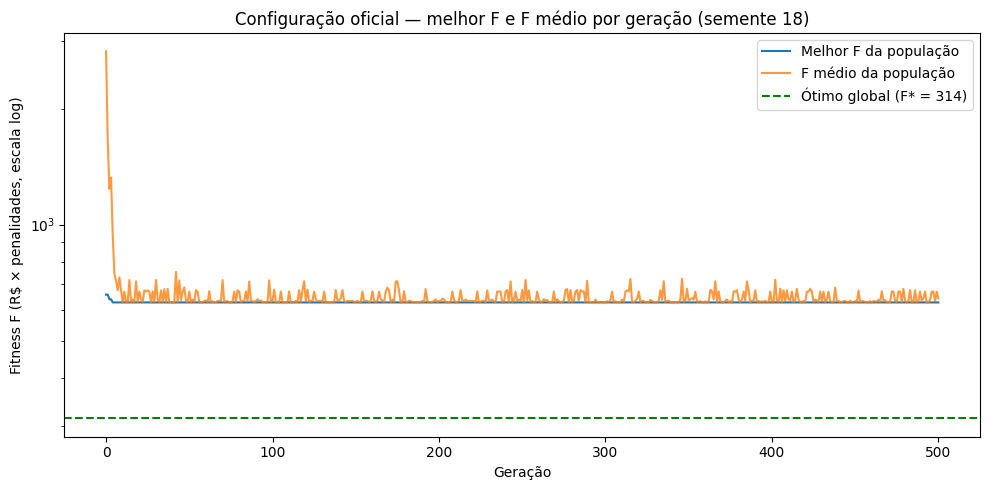

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(hist_melhor_oficial, label="Melhor F da população")
ax.plot(hist_medio_oficial, label="F médio da população", alpha=0.8)
ax.axhline(OTIMO_GLOBAL, color="green", linestyle="--", label=f"Ótimo global (F* = {OTIMO_GLOBAL:g})")
ax.set_yscale("log")
ax.set_xlabel("Geração")
ax.set_ylabel("Fitness F (R$ × penalidades, escala log)")
ax.set_title(f"Configuração oficial — melhor F e F médio por geração (semente {SEMENTE_EXEMPLO})")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretação do gráfico:**

- **Melhor F:** cai nas primeiras gerações e fica constante em 628 a partir da geração 4. Nenhuma melhoria aparece nas quase 500 gerações seguintes.
- **F médio:** cai bruscamente nas primeiras gerações e passa a oscilar logo acima do melhor F. A população fica formada quase só por cópias e pequenas variações da mesma grade. O AG convergiu, mas para um **platô** da função de fitness (um dos problemas de busca local vistos na Aula 5), e não para o ótimo.

**Por que a busca fica parada em F = 628:**

1. Esta grade tem 3 disciplinas dadas por professores que nunca as ministraram. Corrigir **uma** delas não reduz F, porque o fator ×2 continua valendo enquanto restar outra. A melhoria exige várias correções simultâneas, e as grades intermediárias não são recompensadas pelo fitness.
2. Essas grades intermediárias empatam com a elite, todas com F = 628. A ordenação do Python é estável: em caso de empate, mantém na frente os indivíduos que já estavam na elite. Por isso, a elite só muda quando surge um indivíduo **estritamente** melhor.
3. Com mutação de 10% e pais sorteados só na elite, esse indivíduo estritamente melhor raramente aparece.

## 13. Alteração dos parâmetros (item 7)

Uma única execução não basta para comparar configurações de um algoritmo estocástico. Por isso, cada configuração foi executada com as **mesmas 30 sementes (0 a 29)**, o que torna a comparação pareada: para uma dada semente, todas as configurações começam do mesmo gerador de números aleatórios.

**Desenho do estudo.** Partindo da configuração oficial, cada parâmetro é alterado isoladamente:
- mutação: 20%, 30% e 40%;
- elitismo: 10% e 30%;
- gerações: 1000;
- tamanho da população: 120. Não é citado no item 7, mas a Aula 5 o lista entre os parâmetros de um AG.

Por último é avaliada a configuração proposta, que combina população 120 e mutação 30%.

**Métricas de cada configuração**, sobre as 30 execuções:
- melhor e pior F final;
- média, mediana e desvio padrão amostral do F final;
- quantas execuções terminaram com uma grade **sem penalidades** (os três fatores iguais a 1);
- quantas atingiram o **ótimo global** F*;
- geração média de convergência.

*Esta célula executa o AG 270 vezes e leva cerca de 1 minuto.*

In [16]:
SEMENTES = list(range(30))


def configuracao(pop=60, elit=0.20, mut=0.10, ger=500):
    return {"tamanho_populacao": pop, "elitismo": elit, "probabilidade_mutacao": mut, "numero_geracoes": ger}


def executar_experimento(config):
    resultados = []
    for semente in SEMENTES:
        random.seed(semente)
        melhor, fitness, hist_melhor, _ = genetico(professores, **config)
        resultados.append({"semente": semente, "melhor": melhor, "fitness": fitness,
                           "convergencia": geracao_de_convergencia(hist_melhor), "hist_melhor": hist_melhor})
    return resultados


def resumir(resultados):
    fitness = [r["fitness"] for r in resultados]
    sem_penalidade = sum(fatores_penalidade(r["melhor"], professores) == (1.0, 1.0, 1.0) for r in resultados)
    return {
        "Melhor F": min(fitness),
        "Pior F": max(fitness),
        "Média": statistics.mean(fitness),
        "Mediana": statistics.median(fitness),
        "Desvio padrão": statistics.stdev(fitness),
        "Grade sem penalidades": f"{sem_penalidade}/{len(fitness)}",
        "Atingiu o ótimo": f"{sum(abs(f - OTIMO_GLOBAL) < 1e-9 for f in fitness)}/{len(fitness)}",
        "Geração média de convergência": statistics.mean(r["convergencia"] for r in resultados),
    }


NOME_OFICIAL = "Oficial (pop 60, elit 20%, mut 10%, 500 ger.)"
NOME_PROPOSTA = "Proposta (pop 120, mut 30%)"
CONFIGURACOES = {
    NOME_OFICIAL: configuracao(),
    "Mutação 20%": configuracao(mut=0.20),
    "Mutação 30%": configuracao(mut=0.30),
    "Mutação 40%": configuracao(mut=0.40),
    "Elitismo 10%": configuracao(elit=0.10),
    "Elitismo 30%": configuracao(elit=0.30),
    "1000 gerações": configuracao(ger=1000),
    "População 120": configuracao(pop=120),
    NOME_PROPOSTA: configuracao(pop=120, mut=0.30),
}
assert CONFIGURACOES[NOME_OFICIAL] == CONFIG_OFICIAL

resultados_por_config = {nome: executar_experimento(cfg) for nome, cfg in CONFIGURACOES.items()}

tabela_estudo = pd.DataFrame.from_dict(
    {nome: resumir(res) for nome, res in resultados_por_config.items()}, orient="index")
tabela_estudo.index.name = "Configuração (30 sementes cada)"
tabela_estudo.round(1)

,Melhor F,Pior F,Média,Mediana,Desvio padrão,Grade sem penalidades,Atingiu o ótimo,Geração média de convergência
Configuração (30 sementes cada),,,,,,,,
"Oficial (pop 60, elit 20%, mut 10%, 500 ger.)",314.0,628.0,534.9,628.0,137.1,8/30,2/30,23.5
Mutação 20%,314.0,628.0,539.5,628.0,138.3,8/30,1/30,18.6
Mutação 30%,314.0,628.0,530.0,628.0,141.9,9/30,4/30,9.9
Mutação 40%,314.0,628.0,530.1,628.0,141.7,9/30,5/30,11.8
Elitismo 10%,314.0,628.0,544.7,628.0,131.4,7/30,2/30,24.5
Elitismo 30%,314.0,628.0,508.3,628.0,149.3,12/30,2/30,54.0
1000 gerações,314.0,628.0,534.9,628.0,137.1,8/30,2/30,23.5
População 120,314.0,628.0,449.1,335.0,150.7,17/30,6/30,29.4
"Proposta (pop 120, mut 30%)",314.0,628.0,474.0,482.0,156.7,15/30,6/30,15.5


**Leitura do estudo (30 execuções por configuração, sementes 0 a 29).** Os resultados são empíricos: dependem das sementes e do número de execuções. Com 30 execuções, diferenças de poucas unidades nas contagens (ex.: 2/30 × 5/30 no ótimo) estão dentro do que o acaso pode produzir.

- **Em todas as configurações:** o melhor F foi 314 (o ótimo) e o pior foi 628 (o platô da seção 12). O que muda entre elas é quantas execuções escapam do platô.
- **Gerações (500 → 1000):** resultado idêntico ao oficial, ou seja, nenhuma das 30 execuções melhorou depois da geração 500. Em média, o melhor F se estabiliza por volta da geração 24, muito antes do limite.
- **Mutação (10% → 20%, 30%, 40%):** efeito pequeno. A média ficou entre 530,0 e 539,5, e a mediana continuou em 628. As grades sem penalidades ficaram entre 8/30 e 9/30, e as execuções no ótimo variaram de 1/30 a 5/30. Com 30% e 40%, o melhor F se estabilizou mais cedo, em ≈ 10 a 12 gerações.
- **Elitismo (10% / 30%):** com 30%, a média caiu para 508,3 e as grades sem penalidades subiram para 12/30. Mas a mediana continuou 628, só 2/30 atingiram o ótimo e a estabilização ficou mais lenta, com 54 gerações. Com 10%, a média subiu para 544,7.
- **População (60 → 120):** foi a alteração isolada de maior efeito. A média caiu para 449,1 e a mediana para 335; as grades sem penalidades subiram para 17/30 e 6/30 execuções atingiram o ótimo. Uma população maior testa mais combinações antes de a busca estagnar, o que aumenta a chance de a elite já conter uma grade sem penalidades quando o AG para de progredir.

**Resposta ao item 7 e escolha da proposta:**

- **Parâmetros citados no enunciado (elitismo, mutação, gerações):** nenhum mudou o comportamento de forma consistente. Aumentar as gerações não teve efeito algum, porque a busca para muito antes do limite. Mutação e elitismo produziram diferenças pequenas.
- **Tamanho da população:** foi o parâmetro de maior efeito observado.
- **Proposta:** população 120 com mutação 30%, mantendo elitismo 20% e 500 gerações.
  - A população maior ataca a causa observada: pouca diversidade antes da estagnação.
  - A mutação maior, parâmetro citado no item 7, aumenta a variação introduzida a cada geração e acelera a estabilização (9,9 gerações com mutação de 30%, contra 23,5 na oficial).
- **Ressalva:** nestas sementes, aumentar só a população teve média, mediana e número de grades sem penalidades iguais ou melhores que os da proposta, com a mesma taxa de ótimo. A seção 14 discute isso.

## 14. Comparação: configuração oficial × configuração proposta (item 8)

A configuração proposta aumenta a população para 120 e a mutação para 30%, mantendo elitismo de 20% e 500 gerações. A comparação usa as mesmas 30 sementes da seção 13.

Além das estatísticas descritivas, dois testes simples verificam se as diferenças observadas poderiam ser explicadas pelo acaso:
- o **teste de Wilcoxon pareado** compara o F final das duas configurações semente a semente;
- o **teste exato de Fisher** compara a proporção de execuções que atingiram o ótimo.

In [17]:
def descrever(config, resultados):
    return {"População": config["tamanho_populacao"], "Elitismo": f"{config['elitismo']:.0%}",
            "Mutação": f"{config['probabilidade_mutacao']:.0%}", "Gerações": config["numero_geracoes"],
            **{k: (round(v, 2) if isinstance(v, float) else v) for k, v in resumir(resultados).items()}}


res_oficial = resultados_por_config[NOME_OFICIAL]
res_proposta = resultados_por_config[NOME_PROPOSTA]

comparacao = pd.DataFrame({
    "Oficial": descrever(CONFIGURACOES[NOME_OFICIAL], res_oficial),
    "Proposta": descrever(CONFIGURACOES[NOME_PROPOSTA], res_proposta),
})
comparacao.index.name = "Métrica"
display(comparacao)

por_semente = pd.DataFrame({
    "F oficial": [r["fitness"] for r in res_oficial],
    "F proposta": [r["fitness"] for r in res_proposta],
}, index=pd.Index(SEMENTES, name="Semente"))
display(por_semente.T)

diferenca = por_semente["F proposta"] - por_semente["F oficial"]
print(f"Comparação pareada por semente: proposta com F menor em {(diferenca < 0).sum()}, "
      f"igual em {(diferenca == 0).sum()} e maior em {(diferenca > 0).sum()} das {len(SEMENTES)} sementes.")

# consistência: a semente 18 da configuração oficial reproduz a execução detalhada da seção 10
assert res_oficial[SEMENTE_EXEMPLO]["fitness"] == fitness_oficial

,Oficial,Proposta
Métrica,,
População,60,120
Elitismo,20%,20%
Mutação,10%,30%
Gerações,500,500
Melhor F,314.0,314.0
Pior F,628.0,628.0
Média,534.9,474.03
Mediana,628.0,482.0
Desvio padrão,137.15,156.67


Semente,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29
F oficial,628.0,340.0,324.0,628.0,314.0,314.0,628.0,321.0,628.0,628.0,628.0,628.0,332.0,628.0,628.0,333.0,405.0,628.0,628.0,628.0,628.0,628.0,480.0,628.0,628.0,628.0,628.0,628.0,324.0,628.0
F proposta,628.0,320.0,628.0,314.0,325.0,628.0,628.0,628.0,320.0,628.0,628.0,628.0,314.0,314.0,628.0,321.0,320.0,320.0,314.0,628.0,628.0,336.0,314.0,628.0,628.0,325.0,628.0,314.0,628.0,330.0


Comparação pareada por semente: proposta com F menor em 14, igual em 11 e maior em 5 das 30 sementes.


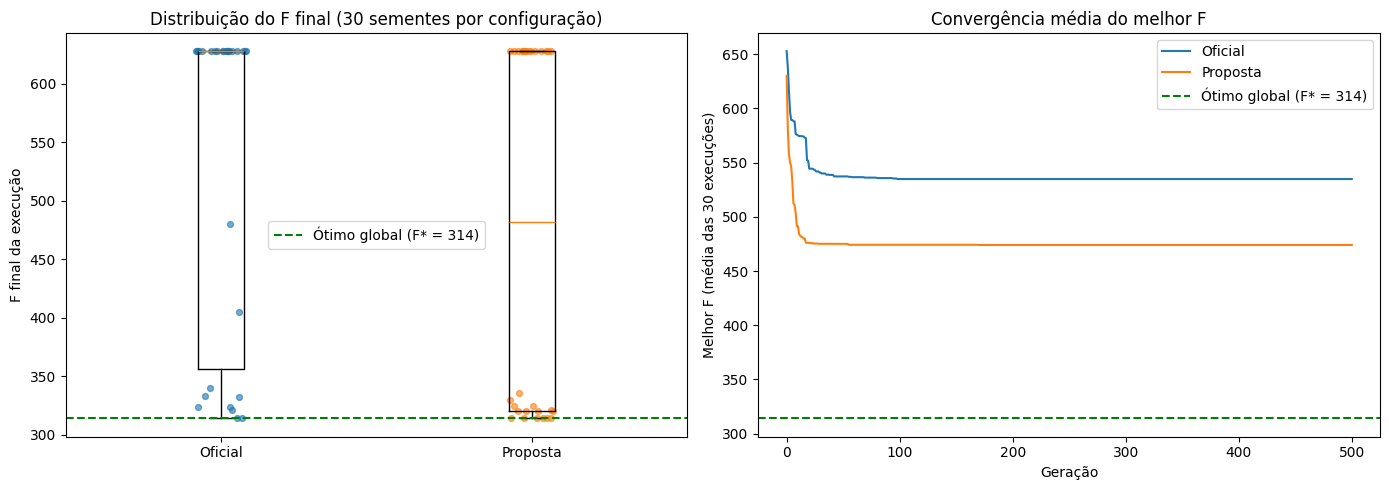

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dados = [por_semente["F oficial"], por_semente["F proposta"]]
axes[0].boxplot(dados, tick_labels=["Oficial", "Proposta"])
rng = np.random.default_rng(0)  # apenas para espalhar horizontalmente os pontos sobrepostos
for i, valores in enumerate(dados, start=1):
    axes[0].scatter(i + rng.uniform(-0.08, 0.08, len(valores)), valores, alpha=0.6, s=18)
axes[0].axhline(OTIMO_GLOBAL, color="green", linestyle="--", label=f"Ótimo global (F* = {OTIMO_GLOBAL:g})")
axes[0].set_ylabel("F final da execução")
axes[0].set_title("Distribuição do F final (30 sementes por configuração)")
axes[0].legend(loc="center")

for nome, rotulo in [(NOME_OFICIAL, "Oficial"), (NOME_PROPOSTA, "Proposta")]:
    curvas = np.array([r["hist_melhor"] for r in resultados_por_config[nome]])
    axes[1].plot(curvas.mean(axis=0), label=rotulo)
axes[1].axhline(OTIMO_GLOBAL, color="green", linestyle="--", label=f"Ótimo global (F* = {OTIMO_GLOBAL:g})")
axes[1].set_xlabel("Geração")
axes[1].set_ylabel("Melhor F (média das 30 execuções)")
axes[1].set_title("Convergência média do melhor F")
axes[1].legend()

plt.tight_layout()
plt.show()

In [19]:
# Wilcoxon pareado: sementes com F igual nas duas configurações são descartadas (padrão do scipy)
teste_pareado = wilcoxon(por_semente["F oficial"], por_semente["F proposta"])
acertos = {col: int(sum(abs(f - OTIMO_GLOBAL) < 1e-9 for f in por_semente[col])) for col in por_semente}
teste_taxa = fisher_exact([[acertos["F oficial"], len(SEMENTES) - acertos["F oficial"]],
                           [acertos["F proposta"], len(SEMENTES) - acertos["F proposta"]]])
print(f"Wilcoxon pareado (F final, oficial x proposta, {len(SEMENTES)} sementes): p = {teste_pareado.pvalue:.3f}")
print(f"Fisher exato (atingiu o ótimo: {acertos['F oficial']}/{len(SEMENTES)} x "
      f"{acertos['F proposta']}/{len(SEMENTES)}): p = {teste_taxa.pvalue:.3f}")

Wilcoxon pareado (F final, oficial x proposta, 30 sementes): p = 0.076
Fisher exato (atingiu o ótimo: 2/30 x 6/30): p = 0.254


**Interpretação (item 8).** Nas 30 execuções realizadas, a configuração proposta apresentou, em relação à oficial:

- média do F final menor (474,03 × 534,9) e mediana menor (482 × 628);
- mais execuções terminando com grade sem penalidades (15/30 × 8/30) e no ótimo global (6/30 × 2/30);
- estabilização mais cedo (15,47 × 23,53 gerações, em média);
- o mesmo melhor (314) e o mesmo pior (628) resultado;
- desvio padrão maior (156,67 × 137,15), reflexo de uma distribuição dividida entre execuções próximas do ótimo e execuções presas em 628 (boxplot);
- na comparação semente a semente, F menor em 14, igual em 11 e maior em 5 das 30 sementes.

O gráfico da direita mostra a média, nas 30 execuções, do melhor F em cada geração. As duas curvas se estabilizam em menos de 100 gerações, e a da proposta fica abaixo da oficial.

**Alcance destas conclusões:**

1. **A diferença não é estatisticamente conclusiva com 30 execuções.** O Wilcoxon pareado (p = 0,076) e o Fisher exato (p = 0,254) não rejeitam, ao nível de 5%, a hipótese de desempenho igual. A tendência observada favorece a proposta, mas confirmá-la exigiria mais execuções.
2. **O efeito observado parece vir da população, e não da mutação.** Na seção 13, aumentar só a população (com mutação de 10%) resultou em média 449,1, mediana 335, 17/30 grades sem penalidades e os mesmos 6/30 no ótimo. Nestas sementes, a mutação de 30% não trouxe benefício adicional observável, além de acelerar a estabilização.
3. **Nenhuma das duas configurações encontra o ótimo de forma confiável.** Nas duas, metade ou mais das execuções termina com alguma penalidade: 22/30 na oficial e 15/30 na proposta.

## 15. Conclusão

- **O problema foi modelado conforme o enunciado?** Sim.
  - O cromossomo tem 5 pares (professor, disciplina), um por dia, com domínios [1, 10] e [1, 20].
  - A função de fitness implementa exatamente a fórmula do enunciado: soma dos custos dos 5 dias multiplicada pelos fatores ×2, ×1,5 e ×5, que podem se combinar.
  - A mutação altera 1 gene por vez dentro do domínio, e o crossover reproduz o exemplo do enunciado.
  - O AG parte do cromossomo inicial dado, com população de tamanho fixo e elitismo.
- **Qual é a melhor grade possível?** F\* = 314. Esse valor é demonstrado por um limite inferior válido para qualquer cromossomo e por uma grade sem penalidades que o atinge: professores 3, 4, 6, 7 e 8, cada um numa disciplina que já ministrou.
- **O AG encontrou soluções válidas?** Sim, mas não em todas as execuções. Na configuração oficial, 8 das 30 execuções terminaram com uma grade sem nenhuma penalidade, 2 delas no ótimo. As demais terminaram com alguma penalidade, a maioria no platô F = 628: os 5 professores mais baratos, mas ao menos um numa disciplina que nunca ministrou.
- **Configuração oficial (item 6).** Na execução detalhada (semente 18), F = 628, estável desde a geração 4. Nas 30 execuções, a média do F final foi 534,9 e a mediana 628.
- **Efeito dos parâmetros (item 7).**
  - Mais gerações não mudaram nada, porque a busca estagna em poucas dezenas de gerações.
  - Mutação e elitismo tiveram efeito pequeno.
  - A população foi o parâmetro de maior efeito observado.
- **Configuração proposta (item 8).** Com população 120 e mutação 30%, nas 30 execuções:
  - a média caiu para 474,03 e a mediana para 482;
  - as grades sem penalidades subiram para 15/30 e as execuções no ótimo para 6/30.

  A diferença em relação à oficial não é estatisticamente conclusiva com esse número de execuções, e o ganho observado vem principalmente do aumento da população.
- **O que os experimentos mostram.** Neste problema, a principal dificuldade do AG é um platô da função de fitness: sair dele exige corrigir várias disciplinas ao mesmo tempo, e o fitness não recompensa as correções parciais. Parâmetros que apenas prolongam a busca, como o número de gerações, não ajudam. O que ajuda é manter mais diversidade antes da estagnação, com uma população maior.

**Reprodutibilidade.** Todos os resultados são empíricos e reprodutíveis. Cada execução do AG fixa sua semente (`random.seed`), e as mesmas sementes (0 a 29) foram usadas em todas as configurações. Outras sementes produzirão números diferentes.